In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from tqdm import tqdm
warnings.filterwarnings('ignore')
%matplotlib inline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import cv2

# Check TensorFlow version
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

2025-12-08 12:01:27.269968: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765195287.536541     666 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765195287.623691     666 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

TensorFlow version: 2.18.0
Keras version: 3.8.0


In [2]:
dataset_path = "/kaggle/input/utkface-new/UTKFace"

In [3]:
image_paths = []
age_labels = []
gender_labels = []

for filename in tqdm(os.listdir(dataset_path)):
    image_path = os.path.join(dataset_path, filename)
    temp = filename.split('_')
    age = int(temp[0])
    gender = int(temp[1])
    image_paths.append(image_path)
    age_labels.append(age)
    gender_labels.append(gender)

100%|██████████| 23708/23708 [00:00<00:00, 457348.59it/s]


In [4]:
df = pd.DataFrame()
df['image'], df['age'], df['gender'] = image_paths, age_labels, gender_labels
df.head()

,image,age,gender
0,/kaggle/input/utkface-new/UTKFace/26_0_2_20170...,26,0
1,/kaggle/input/utkface-new/UTKFace/22_1_1_20170...,22,1
2,/kaggle/input/utkface-new/UTKFace/21_1_3_20170...,21,1
3,/kaggle/input/utkface-new/UTKFace/28_0_0_20170...,28,0
4,/kaggle/input/utkface-new/UTKFace/17_1_4_20170...,17,1


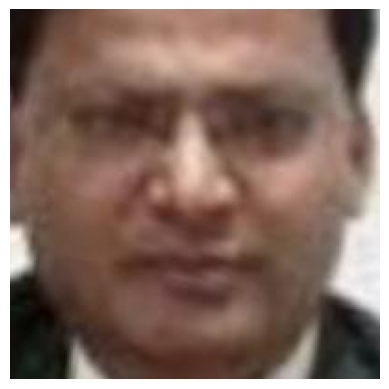

In [5]:
from PIL import Image
img = Image.open(df['image'][20])
plt.axis('off')
plt.imshow(img);

<Axes: xlabel='age', ylabel='Density'>

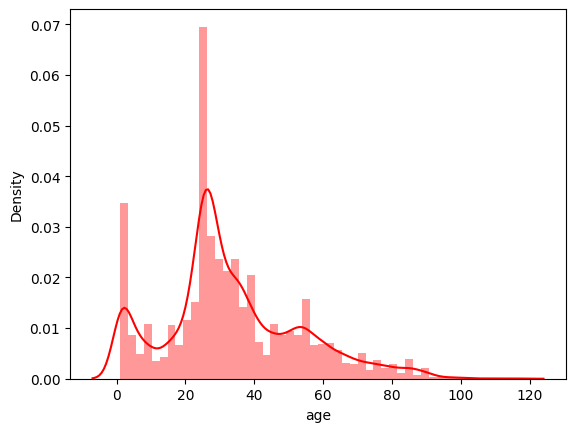

In [6]:
sns.distplot(df['age'] , color = 'red')

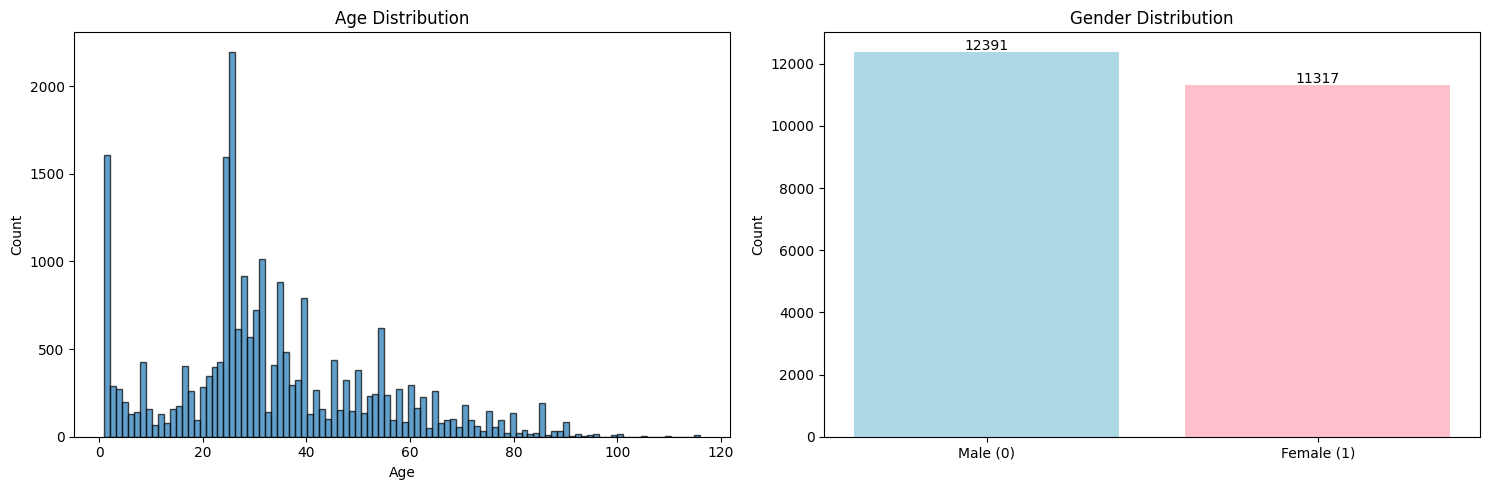

Total images: 23708
Age range: 1 to 116
Gender distribution (0=Male, 1=Female):
gender
0    12391
1    11317
Name: count, dtype: int64
Male count: 12391
Female count: 11317


In [7]:
# Let's explore the dataset distribution with CORRECT gender labels
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age distribution
axes[0].hist(df['age'], bins=100, edgecolor='black', alpha=0.7)
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# Gender distribution - CORRECTED
gender_counts = df['gender'].value_counts()
# 0 = Male, 1 = Female
axes[1].bar(['Male (0)', 'Female (1)'], gender_counts.values, color=['lightblue', 'pink'])
axes[1].set_title('Gender Distribution')
axes[1].set_ylabel('Count')

# Add count labels on bars
for i, count in enumerate(gender_counts.values):
    axes[1].text(i, count + 50, str(count), ha='center')

plt.tight_layout()
plt.show()

print(f"Total images: {len(df)}")
print(f"Age range: {df['age'].min()} to {df['age'].max()}")
print(f"Gender distribution (0=Male, 1=Female):")
print(gender_counts)
print(f"Male count: {gender_counts.get(0, 0)}")
print(f"Female count: {gender_counts.get(1, 0)}")

Preprocessing images: 100%|██████████| 18000/18000 [01:21<00:00, 221.57it/s]


Successfully processed: 18000 images
Failed to load: 0 images
Images shape: (18000, 128, 128, 3)
Ages shape: (18000,)
Genders shape: (18000,)


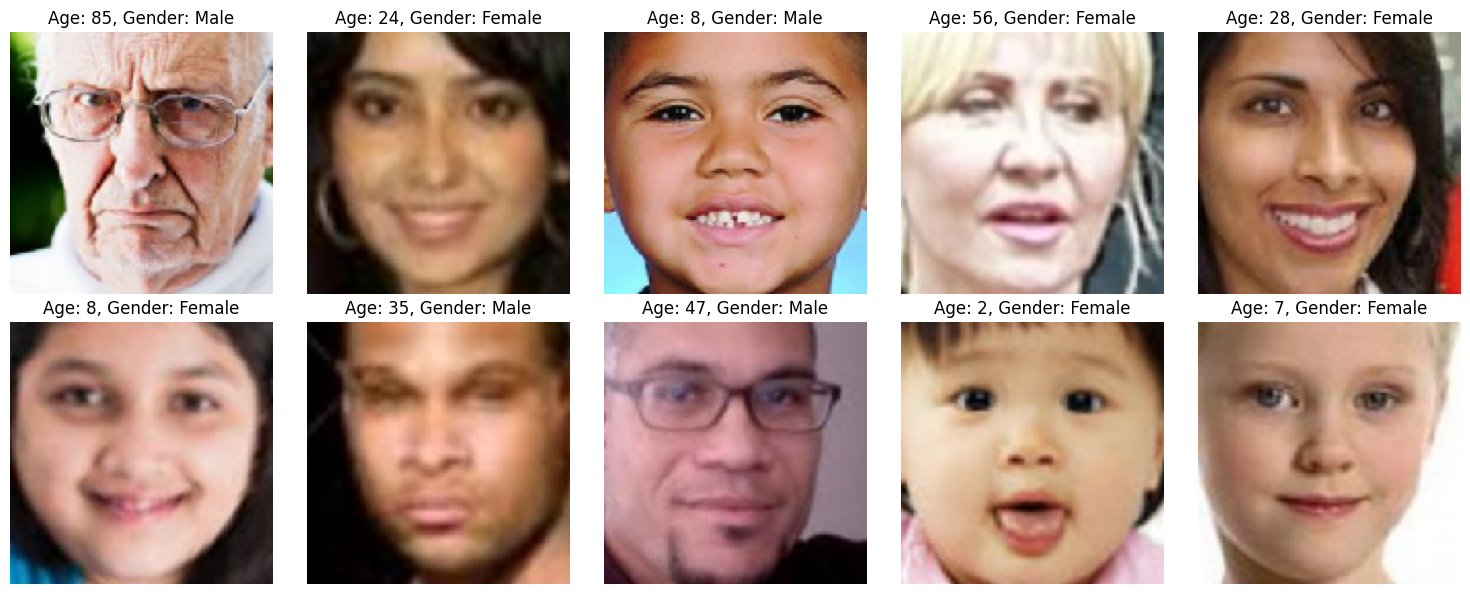

In [8]:
# Define image dimensions
IMG_SIZE = 128

def preprocess_data(df, img_size=IMG_SIZE):
    """
    Preprocess images and labels for training
    """
    images = []
    ages = []
    genders = []
    failed_images = 0
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Preprocessing images"):
        try:
            # Load and resize image
            img = load_img(row['image'], color_mode='rgb', target_size=(img_size, img_size))
            img_array = np.array(img) / 255.0  # Normalize to [0, 1]
            
            images.append(img_array)
            ages.append(row['age'])
            genders.append(row['gender'])
        except Exception as e:
            failed_images += 1
            continue
    
    # Convert to numpy arrays
    images = np.array(images)
    ages = np.array(ages)
    genders = np.array(genders)
    
    print(f"Successfully processed: {len(images)} images")
    print(f"Failed to load: {failed_images} images")
    
    return images, ages, genders

# Let's preprocess a subset first for testing

sample_size = 18000  # Start with smaller sample for testing
df_sample = df.sample(min(sample_size, len(df)), random_state=42)
#df_sample = df.sample(len(df), random_state=42)

# Preprocess data
X, y_age, y_gender = preprocess_data(df_sample)

print(f"Images shape: {X.shape}")
print(f"Ages shape: {y_age.shape}")
print(f"Genders shape: {y_gender.shape}")

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(10):
    ax = axes[i//5, i%5]
    ax.imshow(X[i])
    ax.set_title(f"Age: {y_age[i]}, Gender: {'Male' if y_gender[i] == 0 else 'Female'}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [9]:
# Split data into train, validation, and test sets
X_temp, X_test, y_age_temp, y_age_test, y_gender_temp, y_gender_test = train_test_split(
    X, y_age, y_gender, test_size=0.15, random_state=42
)

X_train, X_val, y_age_train, y_age_val, y_gender_train, y_gender_val = train_test_split(
    X_temp, y_age_temp, y_gender_temp, test_size=0.15, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Training set: 13005 samples
Validation set: 2295 samples
Test set: 2700 samples


In [10]:
def create_multi_task_model(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    """
    Create a multi-task model for age regression and gender classification
    """
    # Input layer
    inputs = Input(shape=input_shape)
    
    # Base CNN layers (shared features)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    x = MaxPooling2D((2, 2))(x)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)
    x = BatchNormalization()(x)
    
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)
    x = BatchNormalization()(x)
    
    x = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)
    x = BatchNormalization()(x)
    
    x = Flatten()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    
    # Age branch (regression)
    age_branch = Dense(64, activation='relu')(x)
    age_branch = Dense(32, activation='relu')(age_branch)
    age_output = Dense(1, activation='linear', name='age_output')(age_branch)
    
    # Gender branch (classification)
    gender_branch = Dense(64, activation='relu')(x)
    gender_branch = Dense(32, activation='relu')(gender_branch)
    gender_output = Dense(1, activation='sigmoid', name='gender_output')(gender_branch)
    
    # Create model
    model = Model(inputs=inputs, outputs=[age_output, gender_output])
    
    return model

# Create model
#model = create_multi_task_model()
#model.summary()

In [11]:
def create_simple_multi_task_model(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    """
    Create a simpler multi-task model for age regression and gender classification
    """
    # Input layer
    inputs = Input(shape=input_shape)
    
    # Base CNN layers (shared features)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(inputs)
    x = MaxPooling2D((2, 2))(x)
    
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)
    
    x = Flatten()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)
    x = Dense(32, activation='relu')(x)
    
    # Age branch (regression)
    age_output = Dense(1, activation='linear', name='age_output')(x)
    
    # Gender branch (classification)
    gender_output = Dense(1, activation='sigmoid', name='gender_output')(x)
    
    # Create model
    model = Model(inputs=inputs, outputs=[age_output, gender_output])
    
    return model

# Create model
model = create_simple_multi_task_model()
model.summary()

# Plot model architecture
plot_model(model, to_file='model_architecture.png', show_shapes=True, show_layer_names=True)

# Define losses and metrics for each output
losses = {
    'age_output': 'mae',  # Mean Absolute Error for age (regression)
    'gender_output': 'binary_crossentropy'  # Binary crossentropy for gender
}

loss_weights = {
    'age_output': 1.0,
    'gender_output': 1.0
}

metrics = {
    'age_output': ['mae'],
    'gender_output': ['accuracy']
}

# Compile model
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss=losses, loss_weights=loss_weights, metrics=metrics)

2025-12-08 12:03:09.614648: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 16384)     │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │  1,048,640 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │         33 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │         33 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,074,370 (4.10 MB)

 Trainable params: 1,074,370 (4.10 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Simple training without data augmentation
batch_size = 32
epochs = 10  # Start with fewer epochs

# Define callbacks
callbacks = [
    # Save best model
    ModelCheckpoint(
        'best_model_simple.h5',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    
    # Early stopping
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# Train the model
history = model.fit(
    X_train,
    {'age_output': y_age_train, 'gender_output': y_gender_train},
    validation_data=(X_val, {'age_output': y_age_val, 'gender_output': y_gender_val}),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - age_output_loss: 17.1702 - age_output_mae: 17.1702 - gender_output_accuracy: 0.5224 - gender_output_loss: 1.2455 - loss: 18.4157
Epoch 1: val_loss improved from inf to 13.97462, saving model to best_model_simple.h5


407/407 ━━━━━━━━━━━━━━━━━━━━ 105s 249ms/step - age_output_loss: 17.1661 - age_output_mae: 17.1662 - gender_output_accuracy: 0.5225 - gender_output_loss: 1.2447 - loss: 18.4109 - val_age_output_loss: 13.3088 - val_age_output_mae: 13.3035 - val_gender_output_accuracy: 0.6562 - val_gender_output_loss: 0.6715 - val_loss: 13.9746
Epoch 2/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - age_output_loss: 13.0545 - age_output_mae: 13.0545 - gender_output_accuracy: 0.6327 - gender_output_loss: 0.6751 - loss: 13.7296
Epoch 2: val_loss improved from 13.97462 to 11.48202, saving model to best_model_simple.h5


407/407 ━━━━━━━━━━━━━━━━━━━━ 102s 250ms/step - age_output_loss: 13.0526 - age_output_mae: 13.0526 - gender_output_accuracy: 0.6327 - gender_output_loss: 0.6750 - loss: 13.7276 - val_age_output_loss: 10.9084 - val_age_output_mae: 10.9111 - val_gender_output_accuracy: 0.7255 - val_gender_output_loss: 0.5716 - val_loss: 11.4820
Epoch 3/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - age_output_loss: 10.8742 - age_output_mae: 10.8742 - gender_output_accuracy: 0.6933 - gender_output_loss: 0.5914 - loss: 11.4656
Epoch 3: val_loss improved from 11.48202 to 11.14254, saving model to best_model_simple.h5


407/407 ━━━━━━━━━━━━━━━━━━━━ 100s 246ms/step - age_output_loss: 10.8734 - age_output_mae: 10.8734 - gender_output_accuracy: 0.6933 - gender_output_loss: 0.5914 - loss: 11.4648 - val_age_output_loss: 10.6047 - val_age_output_mae: 10.6126 - val_gender_output_accuracy: 0.7547 - val_gender_output_loss: 0.5304 - val_loss: 11.1425
Epoch 4/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - age_output_loss: 9.9408 - age_output_mae: 9.9408 - gender_output_accuracy: 0.7228 - gender_output_loss: 0.5598 - loss: 10.5006
Epoch 4: val_loss improved from 11.14254 to 9.70961, saving model to best_model_simple.h5


407/407 ━━━━━━━━━━━━━━━━━━━━ 101s 249ms/step - age_output_loss: 9.9403 - age_output_mae: 9.9404 - gender_output_accuracy: 0.7228 - gender_output_loss: 0.5598 - loss: 10.5002 - val_age_output_loss: 9.2452 - val_age_output_mae: 9.2500 - val_gender_output_accuracy: 0.7904 - val_gender_output_loss: 0.4603 - val_loss: 9.7096
Epoch 5/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - age_output_loss: 9.1834 - age_output_mae: 9.1834 - gender_output_accuracy: 0.7476 - gender_output_loss: 0.5198 - loss: 9.7032
Epoch 5: val_loss did not improve from 9.70961
407/407 ━━━━━━━━━━━━━━━━━━━━ 100s 246ms/step - age_output_loss: 9.1829 - age_output_mae: 9.1829 - gender_output_accuracy: 0.7476 - gender_output_loss: 0.5198 - loss: 9.7027 - val_age_output_loss: 11.5004 - val_age_output_mae: 11.5070 - val_gender_output_accuracy: 0.7704 - val_gender_output_loss: 0.4638 - val_loss: 11.9704
Epoch 6/10
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - age_output_loss: 8.6950 - age_output_mae: 8.6950 - gender_output_accu

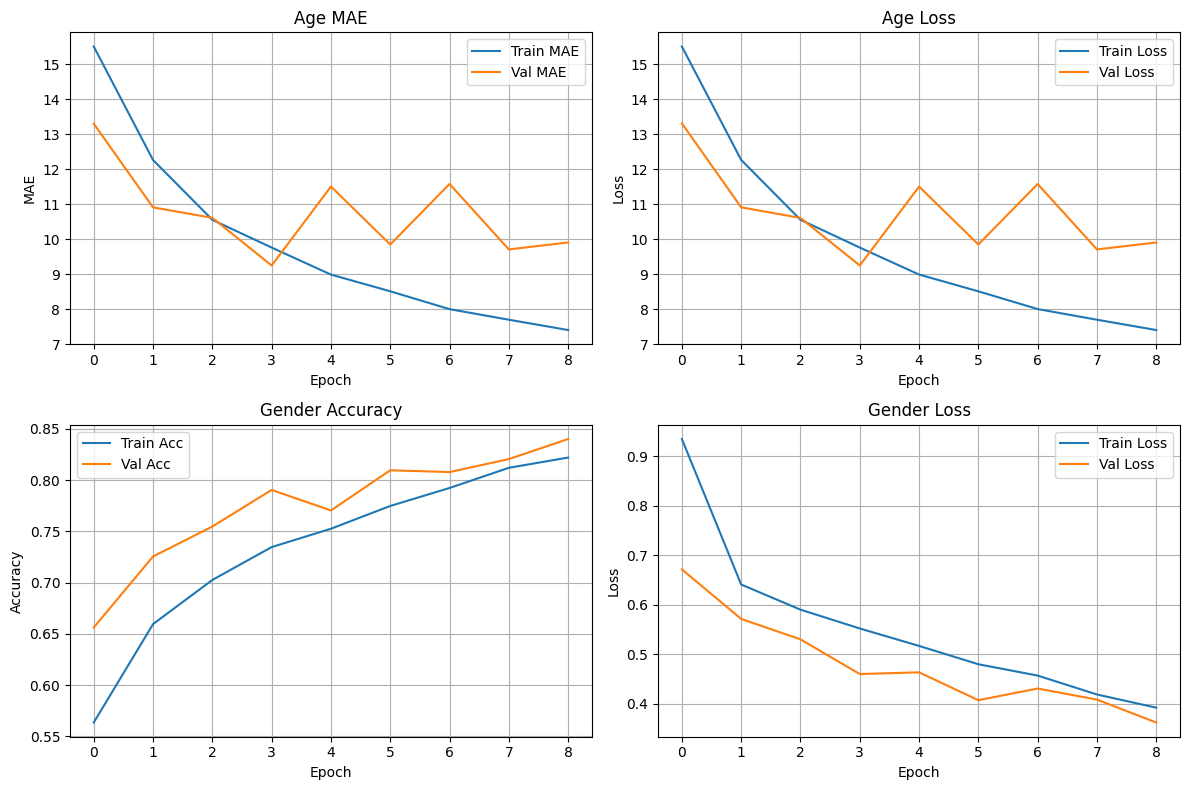

In [13]:
def plot_simple_training_history(history):
    """
    Plot training history for multi-task model
    """
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # Age MAE
    axes[0, 0].plot(history.history['age_output_mae'], label='Train MAE')
    axes[0, 0].plot(history.history['val_age_output_mae'], label='Val MAE')
    axes[0, 0].set_title('Age MAE')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('MAE')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
    
    # Age Loss
    axes[0, 1].plot(history.history['age_output_loss'], label='Train Loss')
    axes[0, 1].plot(history.history['val_age_output_loss'], label='Val Loss')
    axes[0, 1].set_title('Age Loss')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    # Gender Accuracy
    axes[1, 0].plot(history.history['gender_output_accuracy'], label='Train Acc')
    axes[1, 0].plot(history.history['val_gender_output_accuracy'], label='Val Acc')
    axes[1, 0].set_title('Gender Accuracy')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Accuracy')
    axes[1, 0].legend()
    axes[1, 0].grid(True)
    
    # Gender Loss
    axes[1, 1].plot(history.history['gender_output_loss'], label='Train Loss')
    axes[1, 1].plot(history.history['val_gender_output_loss'], label='Val Loss')
    axes[1, 1].set_title('Gender Loss')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Loss')
    axes[1, 1].legend()
    axes[1, 1].grid(True)
    
    plt.tight_layout()
    plt.show()

# Plot training history
plot_simple_training_history(history)

In [14]:
# Evaluate on test set
print("Evaluating on test set...")
test_results = model.evaluate(X_test, {'age_output': y_age_test, 'gender_output': y_gender_test}, verbose=0)

# Print results
print("\nTest Results:")
print(f"Total Loss: {test_results[0]:.4f}")
print(f"Age Loss (MAE): {test_results[1]:.4f}")
print(f"Gender Loss: {test_results[2]:.4f}")
print(f"Age MAE: {test_results[3]:.4f}")
print(f"Gender Accuracy: {test_results[4]:.4f}")

# Make predictions
print("\nMaking predictions on test set...")
predictions = model.predict(X_test, verbose=0)
age_pred = predictions[0]
gender_pred = predictions[1]

# Convert gender predictions to binary (0 or 1)
gender_pred_binary = (gender_pred > 0.5).astype(int)

Evaluating on test set...

Test Results:
Total Loss: 9.8047
Age Loss (MAE): 9.3342
Gender Loss: 0.4412
Age MAE: 9.3635
Gender Accuracy: 0.7959

Making predictions on test set...


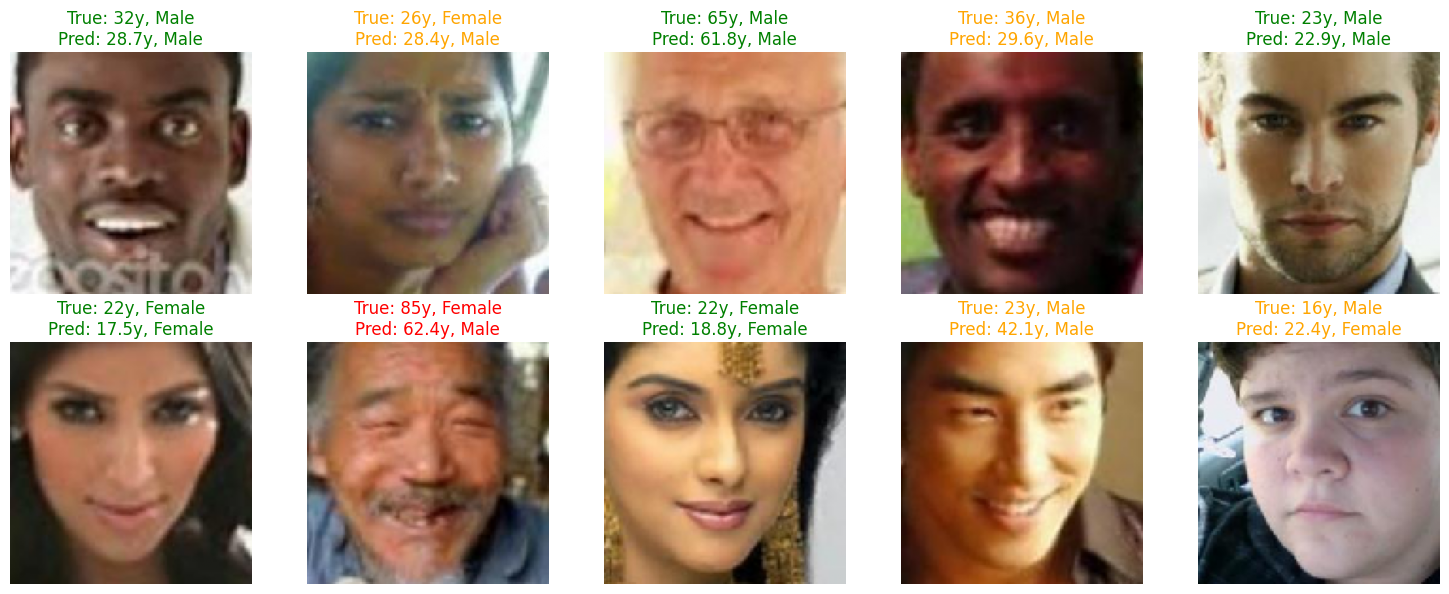


Performance Metrics:
Mean Absolute Error (Age): 9.36 years
Gender Accuracy: 79.59%
Age predictions within 5 years: 40.41%
Age predictions within 10 years: 66.63%


In [15]:
def visualize_predictions(X_images, y_age_true, y_age_pred, y_gender_true, y_gender_pred, num_samples=10):
    """
    Visualize model predictions with CORRECT gender labels
    """
    indices = np.random.choice(len(X_images), num_samples, replace=False)
    
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.ravel()
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        img = X_images[idx]
        
        # Get true and predicted values
        true_age = y_age_true[idx]
        pred_age = y_age_pred[idx][0] if len(y_age_pred.shape) > 1 else y_age_pred[idx]
        
        # CORRECTED: 0 = Male, 1 = Female
        true_gender = "Female" if y_gender_true[idx] == 1 else "Male"
        pred_gender = "Female" if y_gender_pred[idx] == 1 else "Male"
        
        # Display image
        ax.imshow(img)
        ax.axis('off')
        
        # Set title with color coding
        age_error = abs(true_age - pred_age)
        gender_correct = true_gender == pred_gender
        
        if age_error <= 5 and gender_correct:
            title_color = 'green'
        elif age_error <= 10 or gender_correct:
            title_color = 'orange'
        else:
            title_color = 'red'
            
        ax.set_title(f"True: {true_age}y, {true_gender}\n"
                     f"Pred: {pred_age:.1f}y, {pred_gender}",
                     color=title_color)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate and print metrics
    age_errors = np.abs(y_age_true - y_age_pred.flatten())
    gender_accuracy = np.mean(y_gender_true == y_gender_pred.flatten())
    
    print(f"\nPerformance Metrics:")
    print(f"Mean Absolute Error (Age): {np.mean(age_errors):.2f} years")
    print(f"Gender Accuracy: {gender_accuracy:.2%}")
    print(f"Age predictions within 5 years: {np.mean(age_errors <= 5):.2%}")
    print(f"Age predictions within 10 years: {np.mean(age_errors <= 10):.2%}")

visualize_predictions(X_test, y_age_test, age_pred, y_gender_test, gender_pred_binary)

Testing on: /kaggle/input/utkface-new/UTKFace/28_0_0_20170117180555824.jpg.chip.jpg


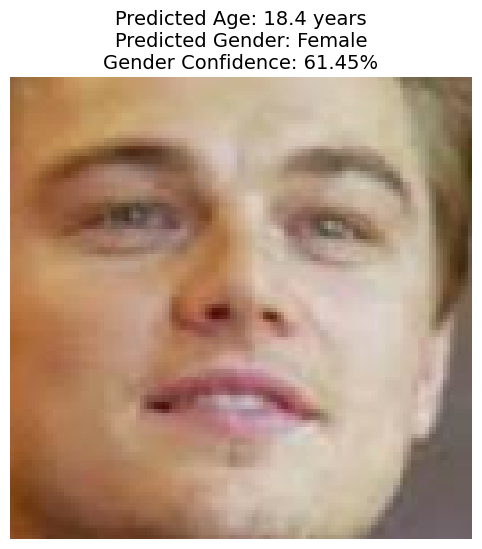

Predicted Age: 18.4 years
Predicted Gender: Female
Gender Confidence: 61.45%


In [16]:
def predict_single_image(image_path, model, img_size=IMG_SIZE):
    """
    Predict age and gender for a single image
    """
    try:
        # Load and preprocess image
        img = load_img(image_path, color_mode='rgb', target_size=(img_size, img_size))
        img_array = np.array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
        
        # Make prediction
        predictions = model.predict(img_array, verbose=0)
        age_pred = predictions[0][0][0]
        gender_pred_prob = predictions[1][0][0]
        
        # Process predictions - CORRECTED
        # In UTKFace: 0 = Male, 1 = Female
        # Sigmoid output > 0.5 means predicted as Female
        predicted_gender = "Female" if gender_pred_prob > 0.5 else "Male"
        gender_confidence = gender_pred_prob if gender_pred_prob > 0.5 else 1 - gender_pred_prob
        
        # Display result
        plt.figure(figsize=(8, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Predicted Age: {age_pred:.1f} years\n"
                  f"Predicted Gender: {predicted_gender}\n"
                  f"Gender Confidence: {gender_confidence:.2%}",
                  fontsize=14)
        plt.show()
        
        return age_pred, predicted_gender, gender_confidence
        
    except Exception as e:
        print(f"Error processing image: {e}")
        return None, None, None

sample_image = df.iloc[3]['image']
print(f"Testing on: {sample_image}")
predicted_age, predicted_gender, confidence = predict_single_image(sample_image, model)

if predicted_age is not None:
    print(f"Predicted Age: {predicted_age:.1f} years")
    print(f"Predicted Gender: {predicted_gender}")
    print(f"Gender Confidence: {confidence:.2%}")

In [17]:
model.save('gender_age_model.h5')
print("Model saved as 'gender_age_model.h5'")

Model saved as 'gender_age_model.h5'
